(46, 41)
1.0


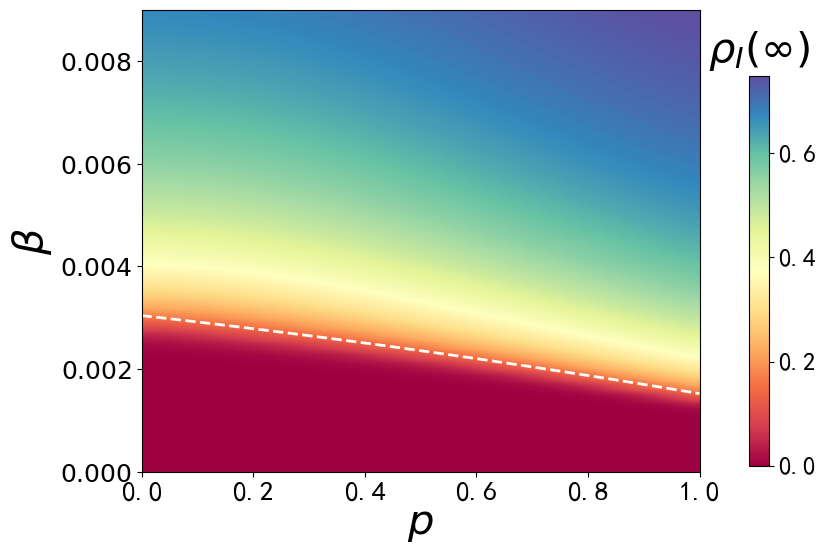

In [22]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import matplotlib.ticker as ticker  # 导入 ticker 用于自定义刻度格式

matplotlib.rcParams['font.sans-serif'] = ['SimHei']  # 设置字体为 SimHei (黑体)
matplotlib.rcParams['axes.unicode_minus'] = False  # 解决坐标轴负号显示问题

p_move_values = np.arange(0.0, 1.025, 0.025)
beta_values = np.arange(0.0, 0.0092, 0.0002)

results_matrix = pd.read_csv('./test2_data/simulation_results_0929.csv', index_col=0)

# 保存对应的beta和p
beta_p_above_threshold = []

for i, p in enumerate(p_move_values):
    for j, beta in enumerate(beta_values):
        if results_matrix.iloc[j, i] > 0.13:
            beta_p_above_threshold.append((beta, p))
            break 

# 将找到的 beta 和 p 提取为单独的列表
beta_above_threshold = [item[0] for item in beta_p_above_threshold]
p_above_threshold = [item[1] for item in beta_p_above_threshold]

# 多项式拟合，degree=2 表示二次多项式
coefficients = np.polyfit(p_above_threshold, beta_above_threshold, 2)

# 生成 p_fit 点，用于绘制平滑的曲线
p_fit = np.linspace(min(p_above_threshold), max(p_above_threshold), 100)

# 计算 p_fit 对应的 beta_fit（二次多项式的值）
beta_fit = np.polyval(coefficients, p_fit)

# 绘制热力图
plt.figure(figsize=(9, 6))
plt.imshow(results_matrix, cmap='Spectral', aspect='auto', origin='lower', interpolation='gaussian',
           extent=[p_move_values[0], p_move_values[-1], beta_values[0], beta_values[-1]])

print(results_matrix.shape)
print(results_matrix.columns[-1])

# 创建 colorbar 并设置标签及刻度字体大小
colorbar = plt.colorbar(label='')
# colorbar.set_label('Colorbar Label', fontsize=16)  # 设置 colorbar 标签字体大小
colorbar.ax.tick_params(labelsize='18')  # 设置 colorbar 刻度标签字体大小
# 移动 colorbar 标签到最上方
colorbar.ax.set_title(r'$\rho_I \left ( \infty \right ) $', fontsize=30, pad=10)  # 设置标签字体大小并调整与colorbar的距离

# 设置 colorbar 的大小（高度）为原图的一半
colorbar.ax.set_position([0.8, 0.12, 0.3, 0.65])  # [left, bottom, width, height]

# 设置x轴和y轴标签
plt.xlabel(r'$p$',fontsize='30')
plt.ylabel(r'$\beta$',fontsize='30')


plt.yticks([0, 0.002, 0.004,0.006,0.008 ], [r'$0.000$', r'$0.002$', r'$0.004$',r'$0.006$',r'$0.008$'], fontsize='18')
plt.xticks(fontsize='20')
# 在原热力图上绘制拟合的二次曲线
plt.plot(p_fit, beta_fit, 'w--', linewidth='2')

# 保存图像
plt.savefig('BA_heatmap.pdf', dpi=300, bbox_inches='tight')
plt.show()
